<center>МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ </center>
<center>ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ ВЫСШЕГО ОБРАЗОВАНИЯ </center>
<center>«НОВОСИБИРСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНИЧЕСКИЙ УНИВЕРСИТЕТ»</center>
<center>Кафедра Вычислительной техники </center>
<br>
<center> <b> <font size="5">  ОТЧЁТ </font>  </b>  </center>   
<center><font size="3">по лабораторной работе №2</font></center>
<center><font size="3">по дисциплине: «Системы искусственного интеллекта и машинное обучение» </font></center>
<br>

Выполнили студенты гр. АВТ-342:
- Звизжева Н.С.

Проверил: Осипенко И.В.

<center>  Новосибирск, 2026  </center>


# Лабораторная работа #2

## Цель работы

Знакомство и работа с алгоритмом машинного обучения - нейронной сетью типа "многослойный перцептрон". Решение задачи регрессии с использованием библиотеки Tensorflow.

## Ход работы
- - - - - - - - -
1. Разобрать и выполнить этапы базового примера (демонстрации и проверки работы нейросети)
2. Загрузить данные
3. Выполнить процедуру НОРМАЛИЗАЦИИ данных и сохранить результат в отдельную таблицу
4. Сформировать обучающую и проверочную части
5. Определить структуру четырех моделей (кол-во узлов на входных, выходных слоях; наличие и кол-во скрытых слоёв; кол-во узлов на скрытых слоях)
6. Для каждой модели (m1-m4) нейронной сети собрать сводную информацию о точности полученных моделей и сделать выводы о влиянии структуры на точность и эффективность применения нейронных сетей на вашем наборе данных.
7. Оценить в минутах время затраченное на выполнение основных этапов текущей работы, согласно методологии CRISP.


# Подключение библиотек

In [1]:
# Проверка версии и пути к выбранному интерпретатору
import sys
print(f"Версия Python - {sys.version}")
print(f"Путь к интерпретатору Python - {sys.executable}")

Версия Python - 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Путь к интерпретатору Python - C:\Python313\python.exe


In [2]:
# Python > 3.8
import pandas as pd
import numpy  as np

import sklearn
from sklearn import linear_model
from sklearn import ensemble
from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler

%matplotlib inline
from matplotlib import pyplot as plt, cm
import seaborn as sns
import plotly.graph_objects as go
from IPython import display
import ipywidgets as widgets

import time

In [3]:
import tensorflow as tf

In [4]:
# Проверка версий библиотек
for lib in [pd, np, sklearn, tf]:
    print(f"{lib.__name__:<12} {lib.__version__}")

pandas       3.0.6
numpy        2.5.3
sklearn      1.9.1
tensorflow   2.20.0


## Объявление функций

Для повышения повторяемости кода и повышения уровня читаемости объявим несколько функций с уже знакомыми операциями

In [5]:
def PLOT34(y_test, y_pred) -> None:
    '''
    Функция построения графиков
    :param y_test: - проверочные значения целевой переменной
    :param y_pred: - вычисленные значения целевой переменной
    '''
    plt.figure(figsize=(12,6))

    # == Диаграмма рассеяния вычисленных значений ==
    # создать первое полотно 121: 1-строк, 2-столбцов, 1-индекс текущего полотна в сетке
    plt.subplot(121)
    plt.scatter(y_test, y_pred,  alpha=0.1, color = "#17becf")
    plt.axline((0, 0), slope=1, color='black', linestyle='--', linewidth=3, alpha=0.7,)
    range_test, range_pred = np.max(y_test)- np.min(y_test) , np.max(y_pred)- np.min(y_pred)
    if range_test/range_pred <4 and range_test/range_pred > 0.25:
        plt.gca().set_aspect('equal')
        axmin, axmax = np.min([y_test, y_pred]), np.max([y_test, y_pred])
        plt.xlim([axmin, axmax]); plt.ylim([axmin, axmax]);
    plt.title('Диаграмма рассеяния вычисленных значений');
    plt.xlabel('Проверочное Y');    plt.ylabel('Вычисленное Y');
    plt.grid(True,  alpha=0.5)   # Сетка

    # == Диаграмма рассеяния ошибок ==
    # создать второе полотно 121: 1-строк, 2-столбцов, 2-индекс текущего полотна в сетке
    plt.subplot(122)
    plt.scatter(y_test, (y_test - y_pred)**2,  alpha=0.1, color = "#17becf")
    plt.title('Диаграмма рассеяния квадрата абсолютной ошибки')
    plt.xlabel('Проверочное Y');    plt.ylabel('Квадрат абсолютной ошибки');
    plt.grid(True,  alpha=0.5)  # Сетка
#--------------------------------------------------------------------------

In [6]:
def GET_METRICS_SINGLE(y_test, y_pred) -> dict:
    '''
    Вычисление и вывод метрик: MAE, RMSE, R2. Используются функции из библиотеки sklearn. На основе сравнения проверочных и вычисленных значений.
    :param y_test: - проверочные значения целевой переменной
    :param y_pred: - вычисленные значения целевой переменной
    Возвращает словарь (хэш-таблицу) со значениями метрик
    '''
    mae  = metrics.mean_absolute_error        (y_test, y_pred)
    mse  = metrics.mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2   = metrics.r2_score                   (y_test, y_pred)
    print ("MAE : {:>9,.3f} (средняя абсолютная ошибка)".format              ( mae ))
    print ("MSE : {:>9,.6f} (среднеквадратичная ошибка)".format( mse ))
    print ("RMSE: {:>9,.6f} (кв. корень из среднеквадратичной ошибки)".format( rmse ))
    print ("R2  : {:>9,.3f} (коэфф. детерминации)".format                    ( r2 ))
    return {"MAE":mae, "MSE":mse, "RMSE":rmse, "R2":r2}
#--------------------------------------------------------------------------

In [7]:
def my3dplot (  x_train: pd.DataFrame, y_train: pd.DataFrame,  isDrawTrain: bool,
                x_test:  pd.DataFrame, y_test: pd.DataFrame,    isDrawTest: bool,
                y_pred:  pd.DataFrame,            isDrawPred: bool,
                x1Name: str, x2Name: str, y_targetName: str,
                pointSize = 5,     # Размер точки
                pointTransparency  = 0.25, # Прозрачность точек графика train, test
                meshTransparency   = 0.5  # Прозрачность поверхности вычисленных значений y_pred
                ) -> None:
    """
    Отображает 3D график исходных и вычисленых точек
    x_test, y_test, x_train, y_train - обучающая и проверочная части исходной таблицы  (тип DataFrame)
    y_pred, - вычисленные значения (тип DataFrame)
    x1Name, x2Name - имя столбца для x1 и x2 (тип строковый)
    y_targetName   - имя столбца целевого    (тип строковый)
    """
    # Построить поверхность, соотвествующую вычисленным значениям
    trace_ModelPredicted = go.Mesh3d(
                       x= x_test[ x1Name ].values,
                       y= x_test[ x2Name ].values,
                       z= y_pred.reshape(-1), # <-- Вычисленные
                       name="Вычисленный",
                       opacity=meshTransparency,
                       #alphahull=1,
                       color='rgb(244,100,100)',  #  rgba(100,244,100, 0.6)
                      )

    # Построить рассеяние обучающих точек
    trace_Train = go.Scatter3d (x= x_train[ x1Name ].values, # <-- Обучающие
                                y= x_train[ x2Name ].values, # <-- Обучающие
                                z= y_train[ y_targetName ].values,     # <-- Обучающие
                                name="Обучающие",
                                mode='markers',
                                marker=dict(
                                    size=pointSize,
                                    color='#1f77b4', # Цвет точек <-- Проверочные
                                    # color=y_train[ y_targetName ].values, # Источник значений цвета <-- Обучающие
                                    # colorscale='Blues',        # Название цветовой шкалы # _r
                                    opacity=pointTransparency
                                ))

    # Построить рассеяние проверочных точек
    trace_Test = go.Scatter3d ( x= x_test[ x1Name ].values,# <-- Проверочные
                                y= x_test[ x2Name ].values,# <-- Проверочные
                                z= y_test[ y_targetName ].values,    # <-- Проверочные
                                name="Проверочные",
                                mode='markers',
                                marker=dict(
                                    size=pointSize,
                                    color='#ff7f0e', # Цвет точек <-- Проверочные
                                    # color=y_test[y_targetName].values, # Источник значений цвета <-- Проверочные
                                    # colorscale='Oranges',        # Название цветовой шкалы # _r
                                    opacity=pointTransparency
                               ))

    # Составить список элементов к отрисовке на графике
    ListForDraw = []
    if isDrawTrain: ListForDraw.append(trace_Train)
    if isDrawTest:  ListForDraw.append(trace_Test)
    if isDrawPred:  ListForDraw.append(trace_ModelPredicted)

    # Отрисовать все указанные элементы
    fig = go.Figure( data=ListForDraw)

    # Добавить подписи осей
    fig.update_layout(
        width=800,
        height=600,
        title='Завиcимость {} от ({}, {})'.format(y_targetName, x1Name, x2Name),
        scene=dict(
            xaxis_title=x1Name,
            yaxis_title=x2Name,
            zaxis_title=y_targetName,
        ),
    )
    fig.show()
#--------------------------------------------------------------------------

In [8]:
def printModelWeights(model):
  # Вывод структуры и значений весовых коэфф. нейросети по слоям
  for layer in model.layers:
      print(f'{"#"*100}')
      print(f"#### Имя слоя:{layer.name};  Тип слоя: {layer.__class__} ##########", end='')
      print(f"\nВид ф-ии активации слоя: {layer.get_config()['activation']}", end='')
      print(f"\nКол-во ВХодов  слоя: {layer.input.shape[1]}", end='')
      print(f"\nКол-во ВЫХодов слоя: {layer.output.shape[1]}", end='')
      if type(layer) is tf.keras.layers.Dense:
          print(f"\nКол-во нейронов слоя:    {layer.get_config()['units']}", end='')
          print(f"\n\nВесовые коэфф. weight_i_j=\n{layer.weights[0].numpy()}")
          print(f"\nВесовые коэфф. bias_i_j=\n{layer.bias.numpy()}")
      elif type(layer) is tf.keras.layers.Activation:
          pass
      print('\n')
#-----------------------

In [9]:
def createObservationsPlot(isUseWidget = False):
  '''  Интерактивный график с двумя линиями'''
  if isUseWidget:
    # прошлый вариант c FigureWidget
    fig = go.FigureWidget(data=[
      go.Scatter(x=xNorm_train.ravel(), y=yNorm_train.ravel(), mode='lines+markers', name='Целевые',  marker=dict(color='black')),
      go.Scatter(x=xNorm_train.ravel(), y=[],  mode='lines+markers', name= f'Вычисленные нейронной сетью значения.',    marker=dict(size=5, color='tomato'))
    ])
  else:
    #  вариант  2026-10-05
    fig = go.Figure(data=[
      go.Scatter(x=xNorm_train.ravel(), y=yNorm_train.ravel(), mode='lines+markers', name='Целевые', marker=dict(color='black')),
      go.Scatter(x=xNorm_train.ravel(), y=[], mode='lines+markers', name='Вычисленные нейронной сетью значения.', marker=dict(size=5, color='tomato'))
    ])

  fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='LightGray')
  fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='LightGray')
  fig.update_layout(
      title="Соотвествие вычисл. зн. с целевыми",
      xaxis_range=[0-0.1, 1+0.1], yaxis_range=[0-0.1, 1+0.1],
      margin=dict(t=40, b=5, l=5, r=5),
      title_y=0.97,
      legend=dict(
          orientation="v",   # Set legend to horizontal
          yanchor="bottom",  xanchor="center", # Anchor the bottom of the legend
          y=-0.23,  x=0.5  ),
      width=400, height=400, )
  return fig



def initObservationsPlot(isUseWidget = False):
    ''' Подготовить и отрисовать  график '''
    fig = createObservationsPlot(isUseWidget)

    # Вар.2. Очищаем контейнер и рисуем заново внутри него
    plot_output.clear_output(wait=True)   # wait=True убирает мигание
    with plot_output:
        display.display(fig)
    # display.display(fig)

    with fig.batch_update(): # Принудительная синхронизация: пустое обновление + пауза
        yNorm_pred = model.predict(xNorm_train, verbose=0) # Вычислить ответы НС
        updateObservationsPlot(fig, 0, yNorm_pred)
    time.sleep(2)  # Дать браузеру время отрисовать виджет
    return fig

def updateObservationsPlot(fig, currEpochNum, yNorm_pred, history=None): #, , epochForTrainInRound
    ''' Обновить значения графика (использует глобалные переменные) '''
    with fig.batch_update(): # Plotly. Обновляем данные внутри виджета напрямую
        fig.update_layout(title_text=f"Соотвествие вычисл. зн. с целевыми.<br>Эпоха: {globalEpochCounter} (текущая {currEpochNum} из {epochForTrainInRound})")
        fig.data[1].y =  yNorm_pred.ravel()
        if history:
            fig.data[1].name = f'Вычисленные нейронной сетью. MSE {history.history["loss"][-1]:>9.6f}'
        else:
            fig.data[1].name = f'Вычисленные нейронной сетью.'


In [10]:
# ── Живой график обучения (без ipywidgets) и итоговая анимация ─────────────────
import io

def figToImage(fig):
    ''' Отрисовать matplotlib-рисунок в PNG фиксированного размера '''
    buf = io.BytesIO()
    fig.savefig(buf, format='png')  # без bbox_inches='tight' -> размер картинки не меняется, график не "прыгает"
    return display.Image(data=buf.getvalue())

def createLivePlot(x, y_true):
    ''' Создать график и вывести его с display_id, чтобы потом обновлять "на месте" (без clear_output) '''
    fig, ax = plt.subplots(figsize=(7, 4.5), dpi=90)
    ax.scatter(x, y_true, s=markerSize, color="black", alpha=transparencyVal, label="Исходные данные")
    predLine, = ax.plot(np.ravel(x), np.full(len(x), np.nan), '.', color="red", markersize=3, label="Вычисленные НС")
    ax.set_xlim(-0.1, 1.1);  ax.set_ylim(-0.1, 1.1)
    ax.set_xlabel("Объясняющий X");  ax.set_ylabel("Целевой Y")
    ax.grid(True, alpha=0.5)
    plt.close(fig)  # чтобы inline-бэкенд не вывел этот рисунок ещё раз в конце ячейки
    handle = display.display(figToImage(fig), display_id=True)
    return fig, predLine, handle

def updateLivePlot(fig, predLine, handle, yNorm_pred, title, loss=np.nan):
    ''' Обновить линию ответов НС и заменить картинку в том же месте вывода '''
    predLine.set_ydata(np.ravel(yNorm_pred))
    predLine.set_label(f"Вычисленные НС. loss {loss:.6f}")
    fig.axes[0].legend(loc='lower right')
    fig.axes[0].set_title(title)
    handle.update(figToImage(fig))

def showTrainingAnimation(x, y_true, snapshots, maxFrames=80, frameDuration=150):
    ''' Plotly-анимация по накопленным снимкам ответов НС (кнопки Play/Pause и ползунок по эпохам) '''
    if not snapshots:
        print("Нет сохранённых снимков - сначала выполните обучение"); return
    step  = int(np.ceil(len(snapshots) / maxFrames))  # прореживание, чтобы анимация не была слишком тяжёлой
    shots = snapshots[::step]
    if shots[-1] is not snapshots[-1]: shots.append(snapshots[-1])  # последний снимок показываем всегда

    x = np.ravel(x)
    def predTrace(s):
        return go.Scatter(x=x, y=s['y'], mode='markers', marker=dict(size=4, color='tomato'), name="Вычисленные НС")
    def frameTitle(s):
        return f"Эпоха {s['epoch']}  |  loss {s['loss']:.6f}"

    frames = [go.Frame(name=str(s['epoch']), data=[predTrace(s)], traces=[1],
                       layout=go.Layout(title_text=frameTitle(s))) for s in shots]
    fig = go.Figure(
        data=[go.Scatter(x=x, y=np.ravel(y_true), mode='markers', marker=dict(size=4, color='black'), opacity=0.3, name='Целевые'),
              predTrace(shots[0])],
        frames=frames)

    animArgs = lambda duration: dict(frame=dict(duration=duration, redraw=True), transition=dict(duration=0), mode='immediate')
    fig.update_layout(
        title_text=frameTitle(shots[0]), width=650, height=520,
        xaxis=dict(range=[-0.1, 1.1], title="Объясняющий X"), yaxis=dict(range=[-0.1, 1.1], title="Целевой Y"),
        margin=dict(t=70, b=110),
        legend=dict(orientation='h', x=1, y=1.02, xanchor='right', yanchor='bottom'),
        updatemenus=[dict(type='buttons', direction='left', showactive=False, x=0, y=-0.13, xanchor='left', yanchor='top',
                          buttons=[dict(label='▶ Play',  method='animate', args=[None, {**animArgs(frameDuration), 'fromcurrent': True}]),
                                   dict(label='❚❚ Pause', method='animate', args=[[None], animArgs(0)])])],
        sliders=[dict(active=0, x=0.22, len=0.78, y=-0.08, currentvalue=dict(visible=False),  # номер эпохи уже есть в заголовке
                      steps=[dict(method='animate', label=f.name, args=[[f.name], animArgs(0)]) for f in frames])],
    )
    fig.show()
#----------------------------------------------------------------------

In [11]:
class GlobalEpochLogger(tf.keras.callbacks.Callback):
    '''  Модифицированный Callback - перехватывает события обучения и выводит нужное сообщение. '''
    def __init__(self):
        super().__init__()
    def on_epoch_end(self, local_epoch, logs=None):
        logs = logs or {}
        loss = logs.get("loss", float("nan"))
        val  = logs.get("val_loss", None)
        val_str = f"  val_loss: {val:.6f}" if val is not None else ""
        print(f"\rЭпоха {globalEpochCounter:>5} (текущая {currEpochNum} из {epochForTrainInRound}) | loss: {loss:.6f}{val_str}", end="", ) #flush=True
#----------------------------------------------------------------------
logShortener = GlobalEpochLogger()

# Tensorflow. Проверка работы нейросети на искусственных данных

Получим модель НС, обученную на  почти "идеальных" входных данных, т.е. с четко прослеживаемой зависимостью переменных и контролируемым уровнем шумов.


## Набор данных для демонстрации

Создадим искусственный набор данных с явной зависимостью ЕДИНСТВЕННОГО `y` от ЕДИНСТВЕННОГО `x`. В качестве зависимости выбрана кусочная функция «Парабола»:

После создания преобразуем данные к типу **pandas.DataFrame**, т.к. загруженные данные по варианту будут иметь указанный тип.

Создадим переменную `X` как набор значений области определения функции в диапазоне  [-1.0, 1.0].

In [12]:
N = 1000 # кол-во точек X
X = np.linspace(-1., 1., N).reshape(-1, 1) # привести массив к столбчатой структуре

Получим набор значения для имитации случайных отклонений для зависимой величины `y`.

In [13]:
noiseLevel= 0.05 # степень зашумленности
Y_noise = np.random.normal(-noiseLevel,noiseLevel,N).reshape(-1, 1)

Объявим вспомогательные переменные для отображения дальнейших графиков.

In [14]:
transparencyVal = 0.3  # Прозрачность точек графика
markerSize = 10        # Размер точки графика



Используя функции различного вида, получим значения `y` для каждого `x`.

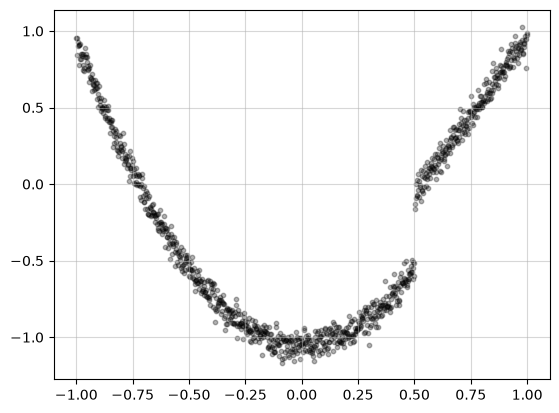

In [15]:
# Парабола
f1 = lambda x: ((x < .5) * np.power(x, 2) + (x > .5) * x) * 2 -1
Y_parabola = f1(X).reshape(-1, 1)
Y_parabola = Y_parabola + Y_noise
plt.scatter(X, Y_parabola, s=markerSize, color="black", alpha=transparencyVal) # Точечная диаграмма
plt.grid(True, alpha=0.5)  # Сетка

In [16]:
x_train = X.copy().reshape(-1,1)   
y_train = Y_parabola.copy().reshape(-1,1)

Нормализуем исходные данные для приведения всех значений к единой шкале. Обратите внимание на значения на осях графика. Подробнее про процедуру нормализации см. в подразделел "Приведение к новой единой шкале. Нормализация"

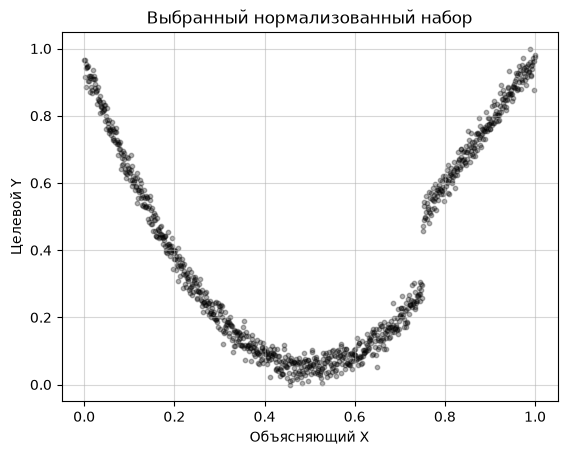

In [17]:
NormalizerX_EXAMPLE = MinMaxScaler().fit(x_train)
NormalizerY_EXAMPLE = MinMaxScaler().fit(y_train)
xNorm_train = NormalizerX_EXAMPLE.transform(x_train)
yNorm_train = NormalizerY_EXAMPLE.transform(y_train)

plt.scatter(xNorm_train, yNorm_train, s=markerSize, color="black", alpha=transparencyVal)
plt.title("Выбранный нормализованный набор")
plt.ylabel("Целевой Y"); plt.xlabel("Объясняющий X");
plt.grid(True, alpha=0.5)  # Сетка.

## Структура и параметры НС

Cоставим код для создания НС.

In [18]:
totalHistoryDict   = dict() 
globalEpochCounter = 0     
trainSnapshots     = []   

# Многослойная
model = tf.keras.models.Sequential()

# Входной слой  -------------------------------------------------------------------------------
model.add( tf.keras.layers.Input(shape=(1 ,))) # Входной слой

# Скрытые слои --------------------------------------------------------------------------------
model.add(tf.keras.layers.Dense(units=100 ,  activation=None,        )) # Скрытй слой, полносвязный, без встроенной нелинейной функции активации
model.add(tf.keras.layers.Activation( activation=tf.keras.activations.relu )) # Обособленный слой с выбранной нелинейной функцией активации

# Дополнительные скрытые слои
model.add(tf.keras.layers.Dense(units=50, activation=None))
model.add(tf.keras.layers.Activation(activation=tf.keras.activations.relu))

# Выходной полносвязный слой, Без нелинейной функции активации --------------------------------
model.add(tf.keras.layers.Dense(units=1,  activation=None))

model.compile(
    # Функции потерь и функции оптимизации
    loss      =tf.keras.losses.MeanSquaredError(), # Выбор функции оценки ошибок/потерь
    optimizer =tf.keras.optimizers.Adam(learning_rate=0.01), #  Выбор функции для минимзации значения выбранной оценки потерь. Adam/SGD
    #metrics   = [tf.keras.losses.MeanSquaredError(), tf.keras.losses.MeanAbsoluteError()] # Дополнительные метрики для оценки ошибок/потерь
)


print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 100)                 │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,301 (20.71 KB)

 Trainable params: 5,301 (20.71 KB)

 Non-trainable params: 0 (0.00 B)

None


Структура сети: входной слой с 1 узлом, два скрытых полносвязных слоя на 100 и 50 нейронов с функцией активации relu, выходной слой из 1 нейрона без функции активации. 

## Первичное и дополнительное обучение

В процессе обучения будем получать вычисленные значения целевой переменной и строить график функции, соответствующий  текущему состоянию нейронной сети. 

True


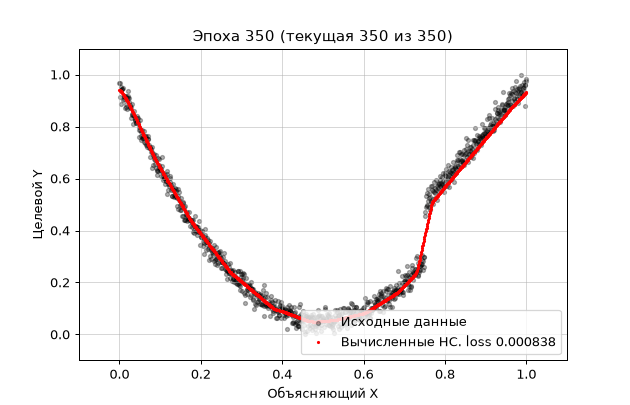

Эпоха   349 (текущая 350 из 350) | loss: 0.000838

In [19]:
# ── Обучающая ячейка (можно запускать многократно) ──────────────────────────────────────────
epochForTrainInRound = 350   # кол-во эпох в текущем запуске ячейки
plotEveryN  = 2             # обновлять график и сохранять снимок каждые N эпох
singleEpoch = 1
# ── Вспомогательный блок для отображения графика функции для единстенного "x"  ──────────────
isDrawable = xNorm_train.shape[1] == 1   # график "x -> y" возможен только при одном входе
print(isDrawable)
if isDrawable:
    figLive, predLine, liveHandle = createLivePlot(xNorm_train, yNorm_train)
    yNorm_pred = model.predict(xNorm_train, verbose=0)
    updateLivePlot(figLive, predLine, liveHandle, yNorm_pred, f"Эпоха {globalEpochCounter} (перед запуском)")
    if not trainSnapshots:   # начальное (необученное) состояние сохраняем один раз
        trainSnapshots.append({'epoch': globalEpochCounter, 'y': yNorm_pred.ravel(), 'loss': np.nan})

# ── Цикл обучения ─────────────────────────────────────────
# 3) Очередной круг ногово или продолжения обучения сети (выполнить epochForTrainInRound итераций по метод по 1 эпохе)
for currEpochNum in range(1, epochForTrainInRound + 1):
    # Непосредственно обучение. Вызов метода fit для настройки коэфф. нейросети
    history = model.fit(
        xNorm_train, yNorm_train, # Обучающие X и Y
        #validation_data=(xNorm_test, yNorm_test), # Опционально проверочные X и Y, для вычисления оценок потерь (loss)
        epochs=singleEpoch,       # Кол-во эпох обучения (в текущей ячейке должно быть равным 1)
        batch_size=200, # Внутри каждой эпохи, проводить обучение пакетами/порциями по batch_size строк
        verbose=0, callbacks=[logShortener],   )
    globalEpochCounter += singleEpoch   # сразу после fit, чтобы заголовок не отставал

    # Сбор и дополнение полной истории обучения
    for key, vals in history.history.items():
        totalHistoryDict.setdefault(key, []).extend(vals)

    #  Каждые N эпох выводить график текущей функции НС. Только в условиях ЕДИНСТВЕННОГО x.
    if isDrawable and (currEpochNum % plotEveryN == 0 or currEpochNum == epochForTrainInRound):
        yNorm_pred = model.predict(xNorm_train, verbose=0)
        loss = history.history['loss'][-1]
        trainSnapshots.append({'epoch': globalEpochCounter, 'y': yNorm_pred.ravel(), 'loss': loss})
        updateLivePlot(figLive, predLine, liveHandle, yNorm_pred,
                       f"Эпоха {globalEpochCounter} (текущая {currEpochNum} из {epochForTrainInRound})", loss)

Осмотрим ещё раз изменения графика функции в процессе обучения

Накоплено снимков: 176


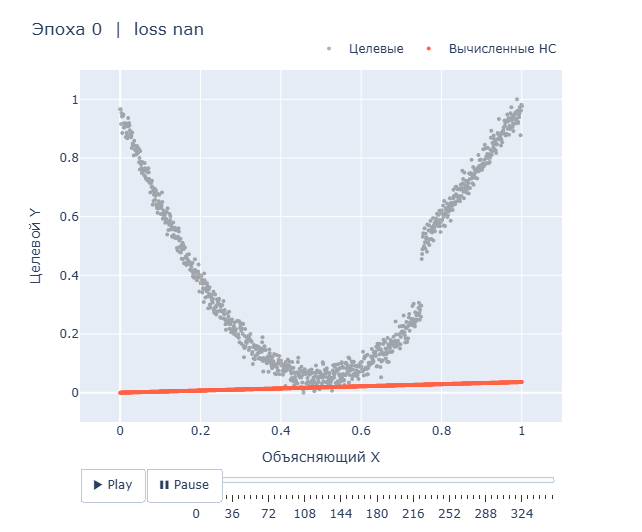

In [20]:
# Анимация по всем накопленным снимкам (после завершения обучения нажмите ▶ Play)
print(f"Накоплено снимков: {len(trainSnapshots)}")
showTrainingAnimation(xNorm_train, yNorm_train, trainSnapshots)

Функция relu выбрана, потому что даёт кусочно-линейную аппроксимацию, подходящую для функции с прямым участком и резким переходом. Сеть с одним скрытым слоем из 100 нейронов достигла loss ≈ 0,002. Итоговая сеть 1 → 100 ReLU → 50 ReLU → 1.

## Оценка точности

Отобразим изменения значений потерь/ошибок по эпохам в виде графика.

Доступные метрики полной истории обучения: dict_keys(['loss'])


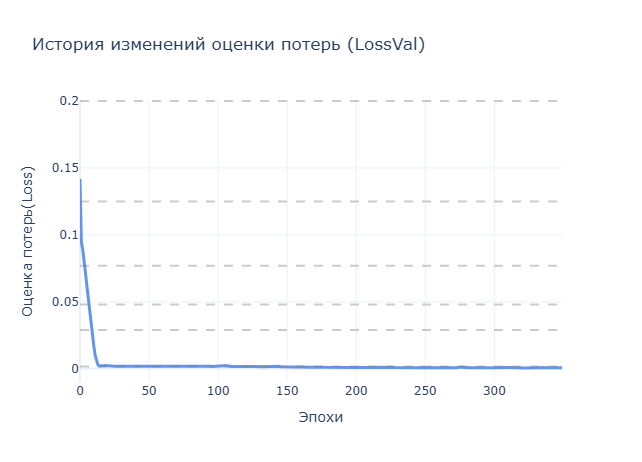

In [21]:
# Отобразить график изменения оценки потерь по эпохам обучения
print('Доступные метрики полной истории обучения:', totalHistoryDict.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
m2 = refHFib<=np.max(totalHistoryDict['loss'])
m2 = np.concatenate([m2[1:], [True]*1])
for y in refHFib[m2]:# Горизонтальные опорные линии (порядки величин)
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

# Настройки осей
fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)") # type="log",
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [22]:
# Осмотрим последние значения выбранной оценки потерь (LossVal = mean_squared_error)
print (totalHistoryDict['loss'][-5:])

[0.0007832800038158894, 0.000762503535952419, 0.0007572275935672224, 0.0007422984926961362, 0.0008381109801121056]


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
MAE :     0.023 (средняя абсолютная ошибка)
MSE :  0.000908 (среднеквадратичная ошибка)
RMSE:  0.030130 (кв. корень из среднеквадратичной ошибки)
R2  :     0.990 (коэфф. детерминации)


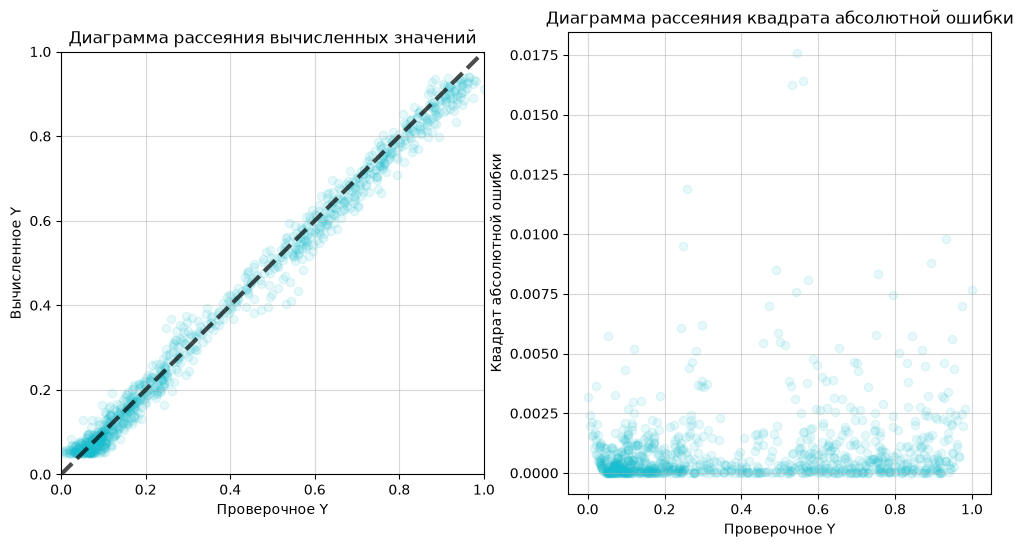

In [23]:
# Вычислить ответы НС
yNorm_pred = model.predict(  xNorm_train  ) # В базовом примере используется проверка на ОБУЧАЮЩЕЙ ЧАСТИ, в дальшейшей работе необходимо проводить проверку на ПРОВЕРОЧНОЙ ЧАСТИ

GET_METRICS_SINGLE(yNorm_train, yNorm_pred)
PLOT34(yNorm_train, yNorm_pred)

В данных есть случайный шум, а его предугадать невозможно, поэтому достичь 100% точности нельзя. Также, нейросеть рисует плавную линию, и резкий скачок в точке разрыва она может только сгладить.

# Загрузка данных по личному варинату

In [24]:
df = pd.read_csv('C:/siimo_labs/var207_Diamonds_price-20260930T020309Z-1-001/var207_Diamonds_price/diamonds_nan_24_PREPARED.csv', # путь к файлу, (используйте автодополнение)
                   sep=',', # разделитель данных в файле
                   header=0, # номер строки с заголовками, нумерация с нуля
                   # header='None', # если заголовки отсутствуют
                  )
print("Размер таблицы", df.shape)
df[:2]

Размер таблицы (48530, 10)


,carat,depth,table,price,x,y,z,color_digit,cut_digit,clarity_digit
0,0.23,61.5,55.0,326.0,3.95,3.98,2.43,6,5,2
1,0.21,59.8,61.0,326.0,3.89,3.84,2.31,6,4,2


# Приведение к новой единой шкале. Нормализация

## Выделение X и Y

Для выполнения следующих шагов разделим исходную таблицу на две отдельных
  - dfX содержащую только объясняющие признаки
  - dfY содержащую только целевой объясняемый признак

In [25]:
features = ['carat', 'color_digit', 'cut_digit',  'clarity_digit', 'x', 'y', 'z', 'depth', 'table']
target   = ['price']

In [26]:
dfX = df[features]
print("Размер таблицы", dfX.shape)
dfX[:2]

Размер таблицы (48530, 9)


,carat,color_digit,cut_digit,clarity_digit,x,y,z,depth,table
0,0.23,6,5,2,3.95,3.98,2.43,61.5,55.0
1,0.21,6,4,2,3.89,3.84,2.31,59.8,61.0


In [27]:
dfY = df[target]
print("Размер таблицы", dfY.shape)
dfY[:2]

Размер таблицы (48530, 1)


,price
0,326.0
1,326.0


## Использование класса MinMaxScaler

In [28]:
scalerNormX = MinMaxScaler()
scalerNormX.fit(dfX)

dfXNorm = pd.DataFrame (
  data    = scalerNormX.transform(dfX), 
  columns = dfX.columns,        
  index   = dfX.index             
)
print("Размер таблицы", dfXNorm.shape)
dfXNorm[:2]

Размер таблицы (48530, 9)


,carat,color_digit,cut_digit,clarity_digit,x,y,z,depth,table
0,0.016667,0.833333,1.00,0.25,0.048140,0.065359,0.321513,0.500000,0.307692
1,0.005556,0.833333,0.75,0.25,0.035011,0.034858,0.293144,0.257143,0.769231


In [29]:
scalerNormY = MinMaxScaler()
scalerNormY.fit(dfY)

dfYNorm = pd.DataFrame (
  data    = scalerNormY.transform(dfY), 
  columns = dfY.columns,          
  index   = dfY.index          
)
print("Размер таблицы", dfYNorm.shape)
dfYNorm[:5]

Размер таблицы (48530, 1)


,price
0,0.000000
1,0.000000
2,0.000685
3,0.000771
4,0.000857


## Проверка нормализации

Осмотрим гистограммы по каждому признаку и проверим их мин. и макс. значения.

In [30]:
dfXNorm.describe().loc[["min", "max" ]]

,carat,color_digit,cut_digit,clarity_digit,x,y,z,depth,table
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [31]:
dfYNorm.describe().loc[["min", "max" ]]

,price
min,0.0
max,1.0


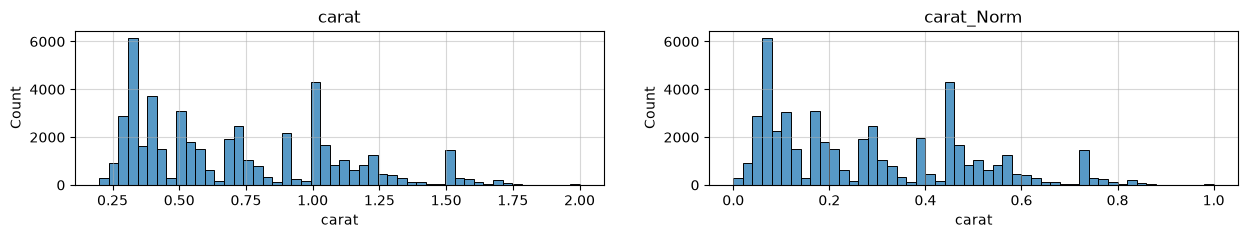

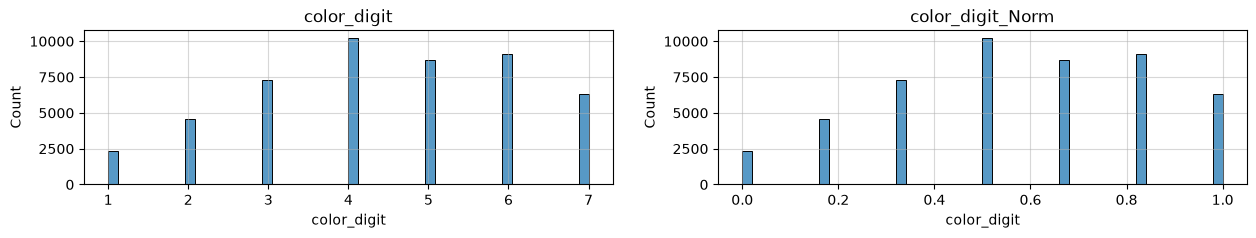

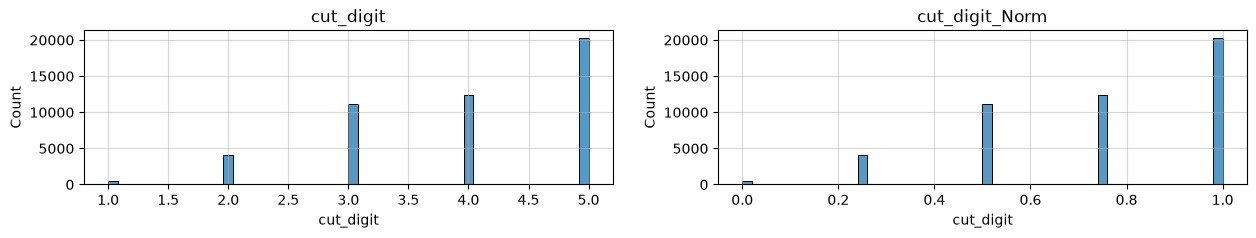

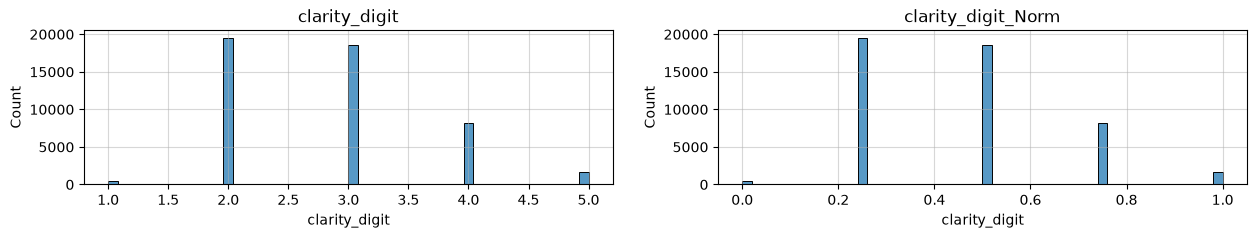

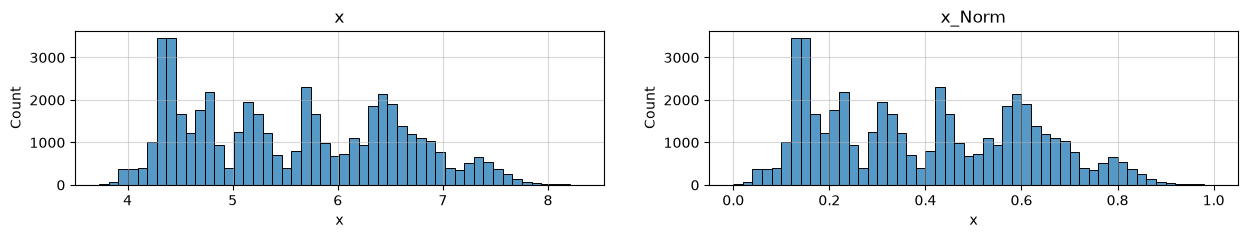

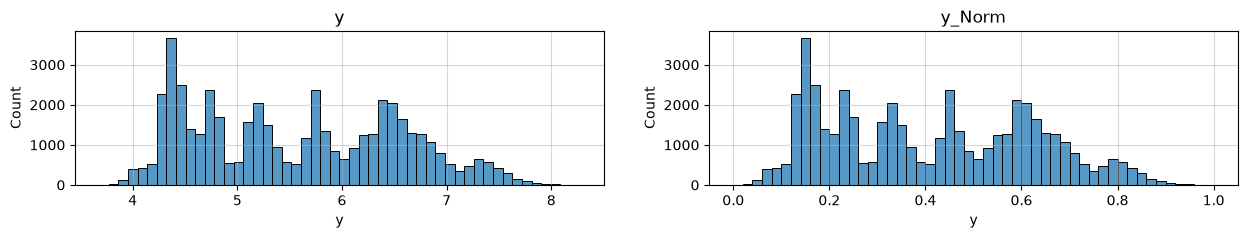

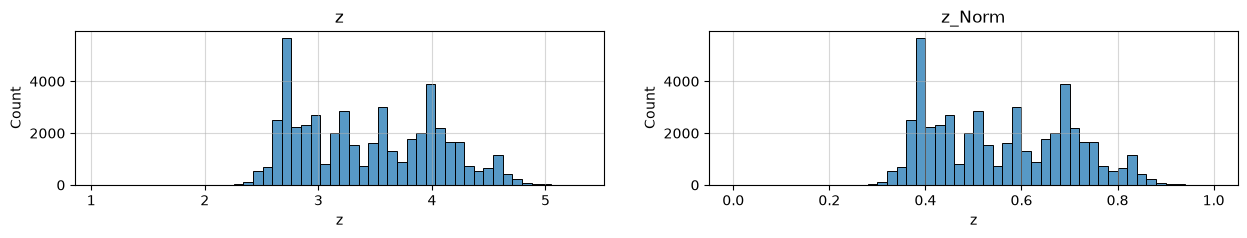

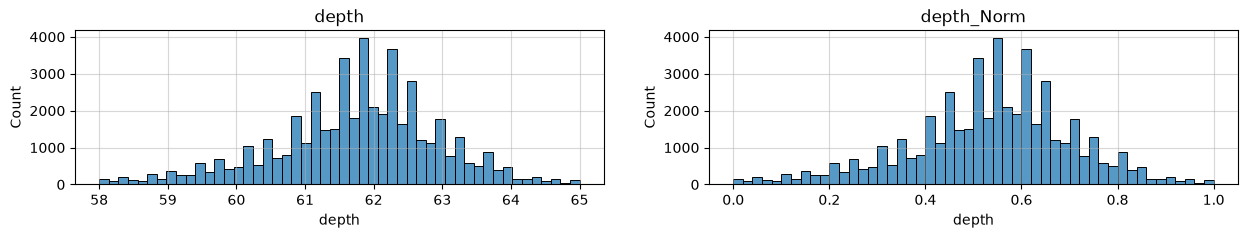

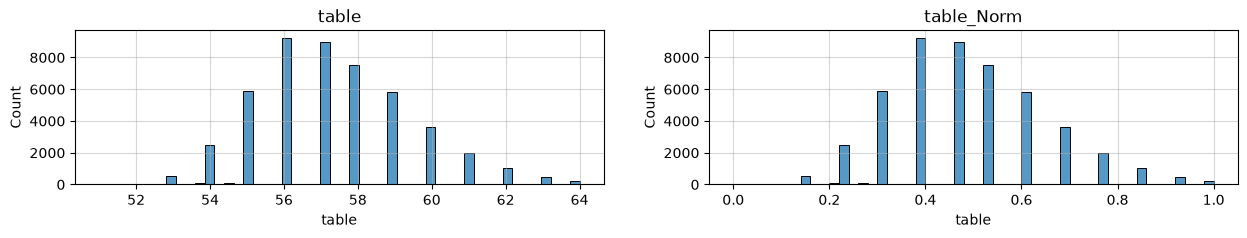

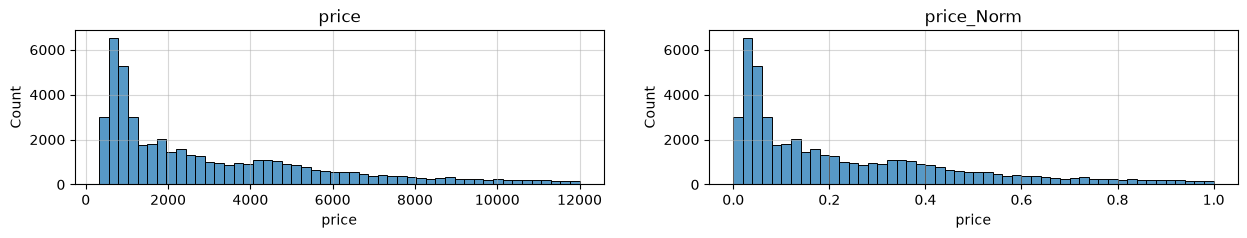

In [32]:
for dfN in [dfXNorm, dfYNorm]:
    for i, colName in enumerate(dfN.columns ):
        #if df[colName].dtype == 'bool': continue
        plt.figure(figsize=(15, 2))

        plt.subplot(1, 2, 1)
        sns.histplot(df[colName], bins=50)
        plt.title(colName)
        plt.grid(True, alpha=0.5) # Сетка.

        plt.subplot(1, 2, 2)
        sns.histplot(dfN[colName], bins=50)
        plt.title(colName+"_Norm")
        plt.grid(True, alpha=0.5)  # Сетка.

# Формирование тренировочной и проверочной выборок

In [33]:
valid_size = 0.3 
rand_seed = 8

## Нормализованые

In [34]:
xNorm_train, xNorm_test, yNorm_train, yNorm_test =  train_test_split(
    dfXNorm[features], 
    dfYNorm[target], 

    test_size    = valid_size, 
    random_state =rand_seed,  
    shuffle=True              
)

In [35]:
xNorm_train[:2]

,carat,color_digit,cut_digit,clarity_digit,x,y,z,depth,table
7921,0.466667,0.666667,1.0,0.25,0.636761,0.631808,0.683215,0.271429,0.384615
33679,0.122222,0.500000,0.5,0.75,0.229759,0.248366,0.432624,0.342857,0.615385


In [36]:
yNorm_train[:2]

,price
7921,0.349238
33679,0.060391


# Нейронная сеть m1. Построение модели без скрытых слоев от ДВУХ "x" (2_вх->1_вых)

## Структура и параметры

In [37]:
totalHistoryDict_m1   = dict() 
globalEpochCounter = 0      # Общий счётчик эпох

model_m1 = tf.keras.models.Sequential()

# Входной слой ------------------------------------------------------------------------------------
model_m1.add(   tf.keras.layers.Input( shape=(2 ,  )
))

# Выходной полносвязный слой, Без нелинейной функции активации -------------------------------------
model_m1.add(    tf.keras.layers.Dense(units=1,  activation=None))


model_m1.compile(
   
    loss      = tf.keras.losses.MeanSquaredError(), # Выбор функции оценки ошибок/потерь
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01), # SGD(learning_rate=0.01) или  Adam(learning_rate=0.01), # Выбор функции для минимзации значения выбранной оценки ошибок/потерь
)


print("Вывод краткой информации о структуре НС")
print(model_m1.summary())

Вывод краткой информации о структуре НС


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 1)                   │               3 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

None


## Первичное и дополнительное обучение

In [38]:
xNorm_train.columns

Index(['carat', 'color_digit', 'cut_digit', 'clarity_digit', 'x', 'y', 'z',
       'depth', 'table'],
      dtype='str')

In [39]:
# Осмотрим используемые для обучения столбцы исходной таблицы
xNorm_train [["carat", "clarity_digit", ]]

,carat,clarity_digit
7921,0.466667,0.25
33679,0.122222,0.75
36835,0.172222,0.25
2382,0.350000,0.25
33687,0.122222,0.50
...,...,...
10376,0.466667,0.25
34949,0.211111,0.25
18417,0.483333,0.50
25940,0.061111,0.50


In [40]:
# Осмотрим используемые для обучения столбцы исходной таблицы
yNorm_train

,price
7921,0.349238
33679,0.060391
36835,0.078636
2382,0.246788
33687,0.060391
...,...
10376,0.392325
34949,0.065873
18417,0.658643
25940,0.034949


In [41]:
epochForTrain_m1 = 20

history_m1 = model_m1.fit(
    xNorm_train [["carat", "clarity_digit", ]], 
    yNorm_train,
    validation_data=( 
        xNorm_test [["carat", "clarity_digit", ]],  
        yNorm_test),
    epochs=epochForTrain_m1,   # кол-во эпох обучения
    #batch_size=100, # внутри каждой эпохи, проводить обучение пакетами/порциями по batch_size строк
    verbose=1,
)

for key in history_m1.history.keys():
    if key not in totalHistoryDict_m1.keys(): totalHistoryDict_m1[key]=list()
    totalHistoryDict_m1[key].extend(history_m1.history[key])

Epoch 1/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0091 - val_loss: 0.0064
Epoch 2/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0064 - val_loss: 0.0064
Epoch 3/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0064 - val_loss: 0.0068
Epoch 4/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0064 - val_loss: 0.0064
Epoch 5/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - loss: 0.0064 - val_loss: 0.0067
Epoch 6/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - loss: 0.0064 - val_loss: 0.0065
Epoch 7/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - loss: 0.0064 - val_loss: 0.0064
Epoch 8/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - loss: 0.0064 - val_loss: 0.0063
Epoch 9/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.0064 - val_loss: 0.0064
Epoch 10/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - loss: 0.0064 - val_loss: 0.0064
Epoch 11/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 0.0064 - val_loss: 0.0068
Epoch 12/20
1062/

## Оценка точности

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


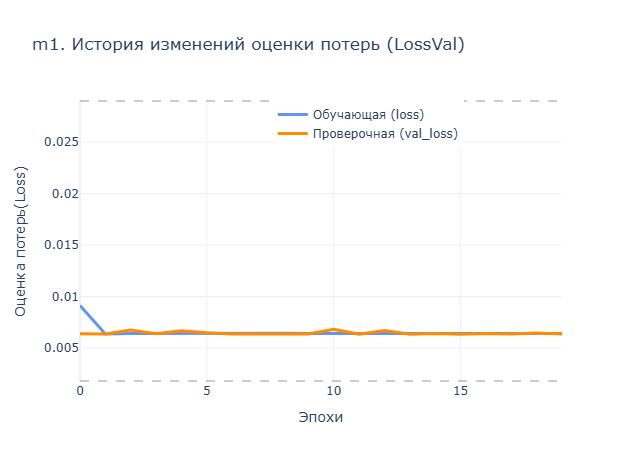

In [42]:
# Отобразить график изменения оценки потерь по эпохам обучения
print('Доступные метрики полной истории обучения:', totalHistoryDict_m1.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict_m1['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict_m1.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict_m1['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
mask = refHFib<=np.max(totalHistoryDict_m1['loss'])
mask = np.concatenate([mask[1:], [True]*1])
for y in refHFib[mask]:# Горизонтальные опорные линии (порядки величин)
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

# Настройки осей
fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)") # type="log",
fig.update_layout(title="m1. История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [43]:
# Осмотрим последние значения выбраной оценки потерь (LossVal = mean_squared_error)
totalHistoryDict_m1['val_loss'][-5:]

[0.006347850896418095,
 0.0064243413507938385,
 0.006356766447424889,
 0.006455366034060717,
 0.006375058088451624]

455/455 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
MAE :     0.056 (средняя абсолютная ошибка)
MSE :  0.006375 (среднеквадратичная ошибка)
RMSE:  0.079844 (кв. корень из среднеквадратичной ошибки)
R2  :     0.886 (коэфф. детерминации)


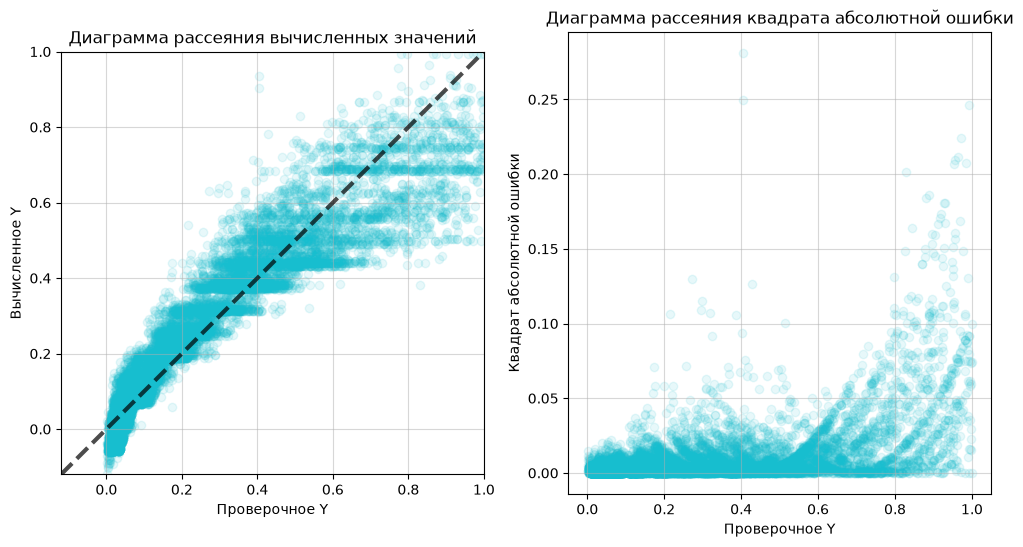

In [44]:
# Вычислить ответы НС на ПРОВЕРОЧНОЙ ЧАСТИ
yNorm_pred_m1 = model_m1.predict( xNorm_test [["carat", "clarity_digit",]] ) # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов

# Вычислить метрики и построить графики, сравнивая ответы НС с ПРОВЕРОЧНОЙ ЧАСТЬЮ
metrics_m1 = GET_METRICS_SINGLE(yNorm_test, yNorm_pred_m1) # Вычислить метрики точности
PLOT34(yNorm_test, yNorm_pred_m1)   # Отобразить графики для вычисленных значений

Значения loss и val_loss стабилизировались уже после 2 эпохи и далее не снижались, поэтому обучение можно было остановить.

## Получение весовых коэфф. w_i и bias для модели m1 (2_вх->1_вых)

In [45]:
printModelWeights(model_m1)

####################################################################################################
#### Имя слоя:dense_3;  Тип слоя: <class 'keras.src.layers.core.dense.Dense'> ##########
Вид ф-ии активации слоя: linear
Кол-во ВХодов  слоя: 2
Кол-во ВЫХодов слоя: 1
Кол-во нейронов слоя:    1

Весовые коэфф. weight_i_j=
[[1.1129194]
 [0.2328478]]

Весовые коэфф. bias_i_j=
[-0.1779965]




Оба веса положительные: чем тяжелее и чище камень, тем выше цена;
Вес carat примерно в 5 раз больше, чем clarity. Признаки нормализованы, поэтому веса сравнимы: вес камня влияет на цену намного сильнее, чем чистота;

## Построение 3d графика зависимости вычисленных значений Y_pred от объясняющих признаков x1 и x2

In [46]:
dfX.columns

Index(['carat', 'color_digit', 'cut_digit', 'clarity_digit', 'x', 'y', 'z',
       'depth', 'table'],
      dtype='str')

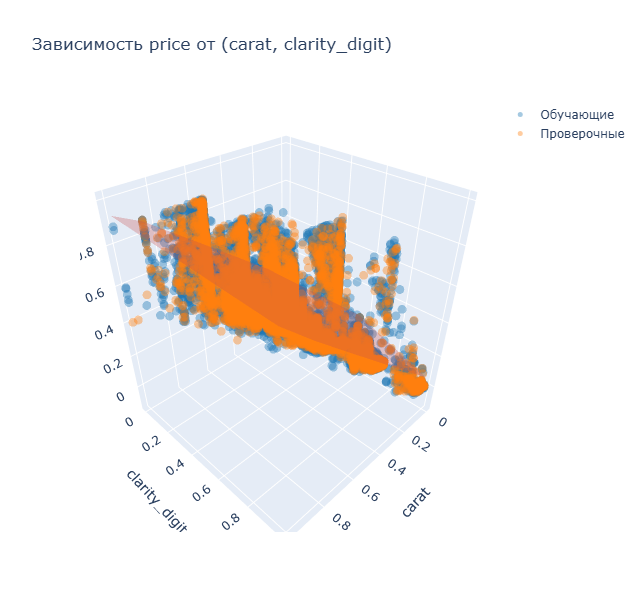

In [47]:
my3dplot(
    xNorm_train, yNorm_train,  True, 
    xNorm_test,  yNorm_test,   True, 
    yNorm_pred_m1,             True, 
    x1Name= "carat",  x2Name="clarity_digit", y_targetName= target[0], # Имена столбцов из таблиц  xNorm_train, xNorm_test, yNorm_pred_m1
    pointSize = 5,    
    pointTransparency  = 0.4, 
    meshTransparency   = 0.3  
)

Каждая лента изогнута вверх: цена растёт с весом всё быстрее.
Чем выше чистота, тем круче лента: при одном и том же весе более чистый камень дорожает быстрее. Признаки влияют на цену не независимо, а усиливая друг друга.
Красная поверхность ответов модели — ровная наклонная плоскость. 

# Нейронная сеть m2. Построение модели со скрытыми слоями от ДВУХ "x" (2_вх-> 100 ReLU -> 50 ReLU ->1_вых)

In [48]:
totalHistoryDict_m2   = dict() 
globalEpochCounter_m2 = 0      # Общий счётчик эпох

model_m2 = tf.keras.models.Sequential()

# Входной слой ------------------------------------------------------------------------------------
model_m2.add(   tf.keras.layers.Input( shape=(2 ,  ) # пример: shape=(1,)
))

model_m2.add(tf.keras.layers.Dense(units=100 ,  activation=None,        )) # Скрытй слой, полносвязный, без встроенной нелинейной функции активации
model_m2.add(tf.keras.layers.Activation( activation=tf.keras.activations.relu ,        )) # Обособленный слой с выбранной нелинейной функцией активации

# Дополнительные скрытые слои
model_m2.add(tf.keras.layers.Dense(units=50, activation=None))
model_m2.add(tf.keras.layers.Activation(activation=tf.keras.activations.relu))

# Выходной полносвязный слой, Без нелинейной функции активации -------------------------------------
model_m2.add(    tf.keras.layers.Dense(units=1,  activation=None))


model_m2.compile(
    loss      = tf.keras.losses.MeanSquaredError(), # Выбор функции оценки ошибок/потерь
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01), # SGD(learning_rate=0.01) или  Adam(learning_rate=0.01), # Выбор функции для минимзации значения выбранной оценки ошибок/потерь
    #metrics  = [tf.keras.losses.MeanSquaredError(), tf.keras.losses.MeanAbsoluteError()] # Дополнительные метрики для оценки ошибок/потерь
)

print("Вывод краткой информации о структуре НС")
print(model_m2.summary())

Вывод краткой информации о структуре НС


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 100)                 │             300 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,401 (21.10 KB)

 Trainable params: 5,401 (21.10 KB)

 Non-trainable params: 0 (0.00 B)

None


In [49]:
epochForTrain_m2 = 20

history_m2 = model_m2.fit(
    xNorm_train [["carat", "clarity_digit", ]],  # обучающие X  # требуется передать таблицу с кол-ом столбцов равным кол-ву входных нейронов
    yNorm_train,  # обучающие Y
    validation_data=(  # опционально: проверочные X и Y
        xNorm_test [["carat", "clarity_digit", ]],  # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов
        yNorm_test),
    epochs=epochForTrain_m2,   # кол-во эпох обучения
    #batch_size=100, # внутри каждой эпохи, проводить обучение пакетами/порциями по batch_size строк
    verbose=1,
)

for key in history_m2.history.keys():
    if key not in totalHistoryDict_m2.keys(): totalHistoryDict_m2[key]=list()
    totalHistoryDict_m2[key].extend(history_m2.history[key])

Epoch 1/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0052 - val_loss: 0.0055
Epoch 2/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0046 - val_loss: 0.0047
Epoch 3/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 4/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0045 - val_loss: 0.0055
Epoch 5/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.0045 - val_loss: 0.0048
Epoch 6/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.0042 - val_loss: 0.0039
Epoch 7/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.0041 - val_loss: 0.0042
Epoch 8/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0041 - val_loss: 0.0041
Epoch 9/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0041 - val_loss: 0.0044
Epoch 10/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0041 - val_loss: 0.0043
Epoch 11/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0041 - val_loss: 0.0040
Epoch 12/20
1062/1062 ━━━━━━━━

## Оценка точности

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


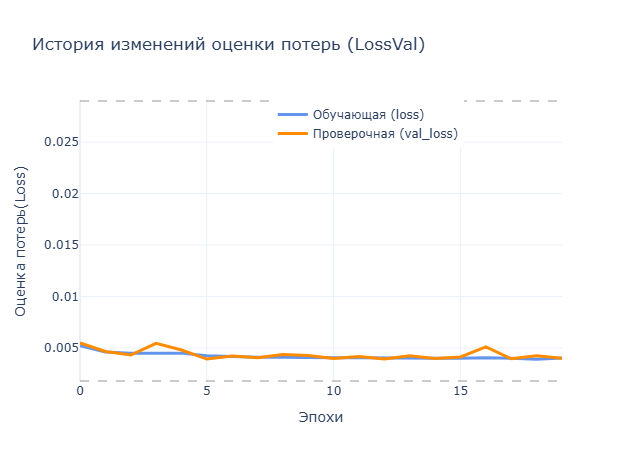

In [50]:
# Отобразить график изменения оценки потерь по эпохам обучения
print('Доступные метрики полной истории обучения:', totalHistoryDict_m2.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict_m2['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict_m2.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict_m2['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
mask = refHFib<=np.max(totalHistoryDict_m2['loss'])
mask = np.concatenate([mask[1:], [True]*1])
for y in refHFib[mask]:# Горизонтальные опорные линии (порядки величин)
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

# Настройки осей
fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)") # type="log",
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [51]:
totalHistoryDict_m2['val_loss'][-5:]

[0.004131031688302755,
 0.005116926971822977,
 0.003960983362048864,
 0.004248526878654957,
 0.004015050362795591]

455/455 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
MAE :     0.040 (средняя абсолютная ошибка)
MSE :  0.004015 (среднеквадратичная ошибка)
RMSE:  0.063364 (кв. корень из среднеквадратичной ошибки)
R2  :     0.928 (коэфф. детерминации)


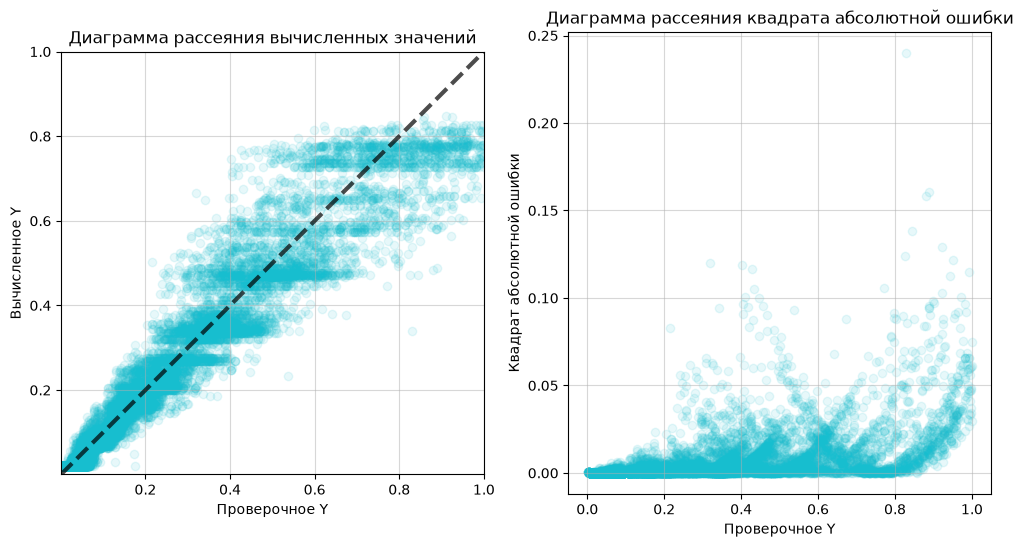

In [52]:
yNorm_pred_m2 = model_m2.predict( xNorm_test [["carat", "clarity_digit",]] ) # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов

GET_METRICS_SINGLE(yNorm_test, yNorm_pred_m2) # Вычислить метрики точности
PLOT34(yNorm_test, yNorm_pred_m2)   # Отобразить графики для вычисленных значений

Первоначальная модель m2 со структурой 2 → 100 → 1 за 20 эпох достигла ошибки ≈ 0,0043. val_loss колебался от 0,0041 до 0,0052. Чтобы повысить точность, в модель добавлен второй скрытый слой из 50 нейронов с функцией активации relu. Значения loss и val_loss близки, переобучения нет.

## Построение 3D графика

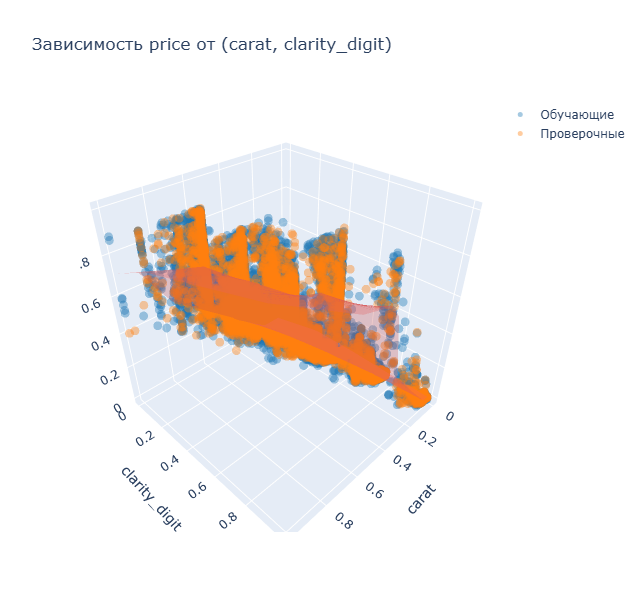

In [53]:
my3dplot(
    xNorm_train, yNorm_train,  True, # Обучающие x и y, Флаг отображения обучающих точек  (синие)
    xNorm_test,  yNorm_test,   True, # Проверочные x и y, Флаг отображения проверочных точек   (оранжевые)
    yNorm_pred_m2,             True, # Вычисленные y, Флаг отображения вычисленной функции  (зелёные)
    x1Name= "carat",  x2Name="clarity_digit", y_targetName= target[0], # Имена столбцов из таблиц  xNorm_train, xNorm_test, yNorm_pred
    pointSize = 5,     # Размер точки
    pointTransparency  = 0.4, # Прозрачность точек графика train, test
    meshTransparency   = 0.3  # Прозрачность поверхности вычисленных значений y_pred
)

# Нейронная сеть m3. Построение модели без скрытых слоев от множества "x"  (9_вх->1_вых))

In [54]:
totalHistoryDict_m3   = dict() # Вспомогательный словарь для хранения  для хранение полной истории обучения - списков значений метрик
globalEpochCounter_m3 = 0      # Общий счётчик эпох

model_m3 = tf.keras.models.Sequential()

# Входной слой ------------------------------------------------------------------------------------
model_m3.add(   tf.keras.layers.Input( shape=(9 ,  ) # пример: shape=(1,)
))

# Выходной полносвязный слой, Без нелинейной функции активации -------------------------------------
model_m3.add(    tf.keras.layers.Dense(units=1,  activation=None))


model_m3.compile(
    loss      = tf.keras.losses.MeanSquaredError(), # Выбор функции оценки ошибок/потерь
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01), # SGD(learning_rate=0.01) или  Adam(learning_rate=0.01), # Выбор функции для минимзации значения выбранной оценки ошибок/потерь
    #metrics  = [tf.keras.losses.MeanSquaredError(), tf.keras.losses.MeanAbsoluteError()] # Дополнительные метрики для оценки ошибок/потерь
)

print("Вывод краткой информации о структуре НС")
print(model_m3.summary())

Вывод краткой информации о структуре НС


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 1)                   │              10 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10 (40.00 B)

 Trainable params: 10 (40.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [55]:
epochForTrain_m3 = 20

history_m3 = model_m3.fit(
    xNorm_train [["carat", "color_digit", "cut_digit", "clarity_digit", 'x', 'y', 'z', 'depth', 'table']],  # обучающие X  # требуется передать таблицу с кол-ом столбцов равным кол-ву входных нейронов
    yNorm_train,  # обучающие Y
    validation_data=(  # опционально: проверочные X и Y
        xNorm_test [["carat", "color_digit", "cut_digit", "clarity_digit", 'x', 'y', 'z', 'depth', 'table']],  # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов
        yNorm_test),
    epochs=epochForTrain_m3,   # кол-во эпох обучения
    #batch_size=100, # внутри каждой эпохи, проводить обучение пакетами/порциями по batch_size строк
    verbose=1,
)

for key in history_m3.history.keys():
    if key not in totalHistoryDict_m3.keys(): totalHistoryDict_m3[key]=list()
    totalHistoryDict_m3[key].extend(history_m3.history[key])

Epoch 1/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0118 - val_loss: 0.0066
Epoch 2/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0059 - val_loss: 0.0055
Epoch 3/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0056 - val_loss: 0.0053
Epoch 4/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0055 - val_loss: 0.0057
Epoch 5/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0055 - val_loss: 0.0056
Epoch 6/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0054 - val_loss: 0.0052
Epoch 7/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0054 - val_loss: 0.0053
Epoch 8/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.0055 - val_loss: 0.0059
Epoch 9/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0054 - val_loss: 0.0055
Epoch 10/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 0.0054 - val_loss: 0.0053
Epoch 11/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0054 - val_loss: 0.0074
Epoch 12/20
1062/1062 ━━━━━━━━

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


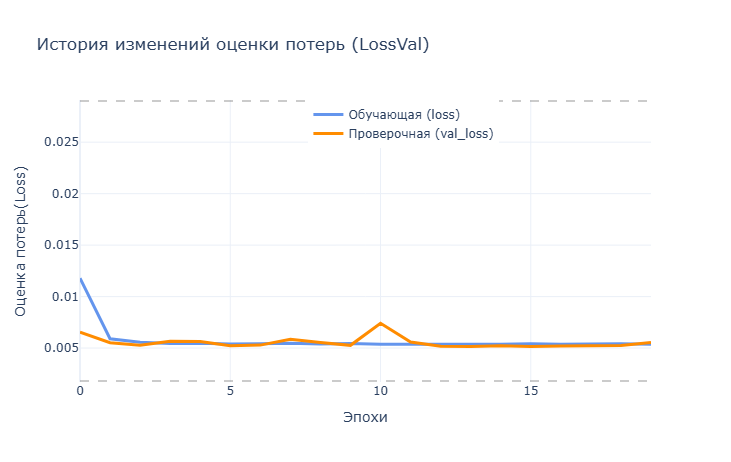

In [56]:
# Отобразить график изменения оценки потерь по эпохам обучения
print('Доступные метрики полной истории обучения:', totalHistoryDict_m3.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict_m3['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict_m3.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict_m3['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
mask = refHFib<=np.max(totalHistoryDict_m3['loss'])
mask = np.concatenate([mask[1:], [True]*1])
for y in refHFib[mask]:# Горизонтальные опорные линии (порядки величин)
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

# Настройки осей
fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)") # type="log",
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [57]:
totalHistoryDict_m3['val_loss'][-5:]

[0.005150936543941498,
 0.0052057295106351376,
 0.005196109879761934,
 0.005254225339740515,
 0.005552380811423063]

455/455 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
MAE :     0.050 (средняя абсолютная ошибка)
MSE :  0.005552 (среднеквадратичная ошибка)
RMSE:  0.074514 (кв. корень из среднеквадратичной ошибки)
R2  :     0.901 (коэфф. детерминации)


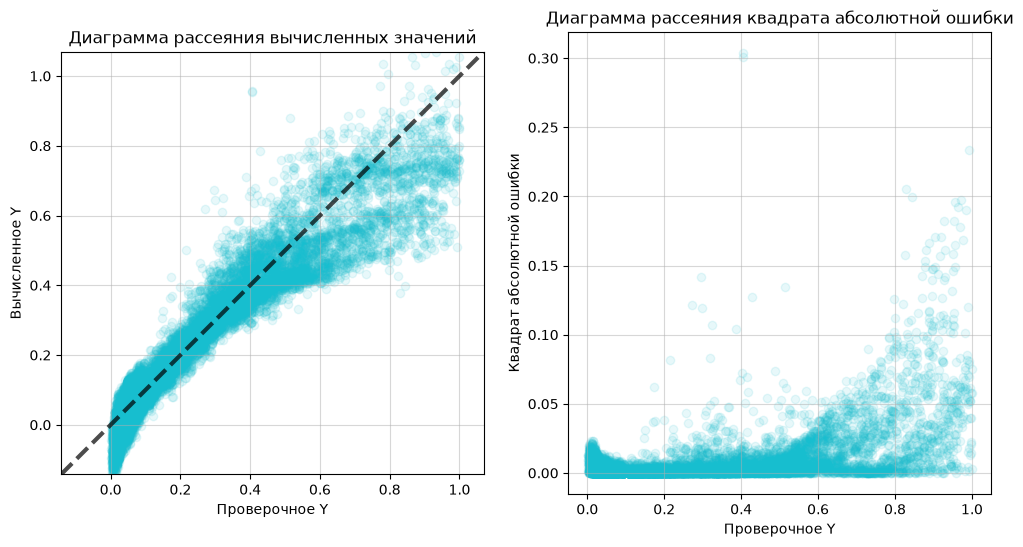

In [58]:
# Вычислить ответы НС на ПРОВЕРОЧНОЙ ЧАСТИ
yNorm_pred_m3 = model_m3.predict( xNorm_test [["carat", "color_digit", "cut_digit", "clarity_digit", 'x', 'y', 'z', 'depth', 'table']] ) # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов

# Вычислить метрики и построить графики, сравнивая ответы НС с ПРОВЕРОЧНОЙ ЧАСТЬЮ
GET_METRICS_SINGLE(yNorm_test, yNorm_pred_m3) # Вычислить метрики точности
PLOT34(yNorm_test, yNorm_pred_m3)   # Отобразить графики для вычисленных значений

In [59]:
printModelWeights(model_m3)

####################################################################################################
#### Имя слоя:dense_7;  Тип слоя: <class 'keras.src.layers.core.dense.Dense'> ##########
Вид ф-ии активации слоя: linear
Кол-во ВХодов  слоя: 9
Кол-во ВЫХодов слоя: 1
Кол-во нейронов слоя:    1

Весовые коэфф. weight_i_j=
[[ 1.5936911 ]
 [ 0.09867228]
 [ 0.02420797]
 [ 0.23715518]
 [-0.40758297]
 [ 0.06019665]
 [-0.11584654]
 [-0.02833331]
 [-0.03305971]]

Весовые коэфф. bias_i_j=
[-0.18141763]




# Нейронная сеть m4. Построение модели со скрытыми слоями от множества "x"  (9_вх-> 100 ReLU -> 50 ReLU ->1_вых)

In [60]:
totalHistoryDict_m4   = dict() # Вспомогательный словарь для хранения  для хранение полной истории обучения - списков значений метрик
globalEpochCounter_m4 = 0      # Общий счётчик эпох

model_m4 = tf.keras.models.Sequential()

# Входной слой ------------------------------------------------------------------------------------
model_m4.add(   tf.keras.layers.Input( shape=(9 ,  ))) # пример: shape=(1,)

model_m4.add(tf.keras.layers.Dense(units=100 ,  activation=None,        )) # Скрытй слой, полносвязный, без встроенной нелинейной функции активации
model_m4.add(tf.keras.layers.Activation( activation=tf.keras.activations.relu ,        )) # Обособленный слой с выбранной нелинейной функцией активации

model_m4.add(tf.keras.layers.Dense(units=50 ,  activation=None,        )) # Скрытй слой, полносвязный, без встроенной нелинейной функции активации
model_m4.add(tf.keras.layers.Activation( activation=tf.keras.activations.relu ,        )) # Обособленный слой с выбранной нелинейной функцией активации
    
# Выходной полносвязный слой, Без нелинейной функции активации -------------------------------------
model_m4.add(    tf.keras.layers.Dense(units=1,  activation=None))


model_m4.compile(
    # Функции оценки потерь, функции оптимизации, метрики
    loss      = tf.keras.losses.MeanSquaredError(), # Выбор функции оценки ошибок/потерь
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01), # SGD(learning_rate=0.01) или  Adam(learning_rate=0.01), # Выбор функции для минимзации значения выбранной оценки ошибок/потерь
    #metrics  = [tf.keras.losses.MeanSquaredError(), tf.keras.losses.MeanAbsoluteError()] # Дополнительные метрики для оценки ошибок/потерь
)

print("Вывод краткой информации о структуре НС")
print(model_m4.summary())

Вывод краткой информации о структуре НС


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 100)                 │           1,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_4 (Activation)            │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_5 (Activation)            │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,101 (23.83 KB)

 Trainable params: 6,101 (23.83 KB)

 Non-trainable params: 0 (0.00 B)

None


In [61]:
epochForTrain_m4 = 20

history_m4 = model_m4.fit(
    xNorm_train [["carat", "color_digit", "cut_digit", "clarity_digit", 'x', 'y', 'z', 'depth', 'table']],  # обучающие X  # требуется передать таблицу с кол-ом столбцов равным кол-ву входных нейронов
    yNorm_train,  # обучающие Y
    validation_data=(  # опционально: проверочные X и Y
        xNorm_test [["carat", "color_digit", "cut_digit", "clarity_digit", 'x', 'y', 'z', 'depth', 'table']],  # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов
        yNorm_test),
    epochs=epochForTrain_m4,   # кол-во эпох обучения
    #batch_size=100, # внутри каждой эпохи, проводить обучение пакетами/порциями по batch_size строк
    verbose=1,
)

for key in history_m4.history.keys():
    if key not in totalHistoryDict_m4.keys(): totalHistoryDict_m4[key]=list()
    totalHistoryDict_m4[key].extend(history_m4.history[key])

Epoch 1/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0041 - val_loss: 0.0020
Epoch 2/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0024 - val_loss: 0.0020
Epoch 3/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0024 - val_loss: 0.0028
Epoch 4/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0022 - val_loss: 0.0027
Epoch 5/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0022 - val_loss: 0.0020
Epoch 6/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 7/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0021 - val_loss: 0.0021
Epoch 8/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 9/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0021 - val_loss: 0.0017
Epoch 10/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0021 - val_loss: 0.0022
Epoch 11/20
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 12/20
1062/1062 ━━━━━━━━

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


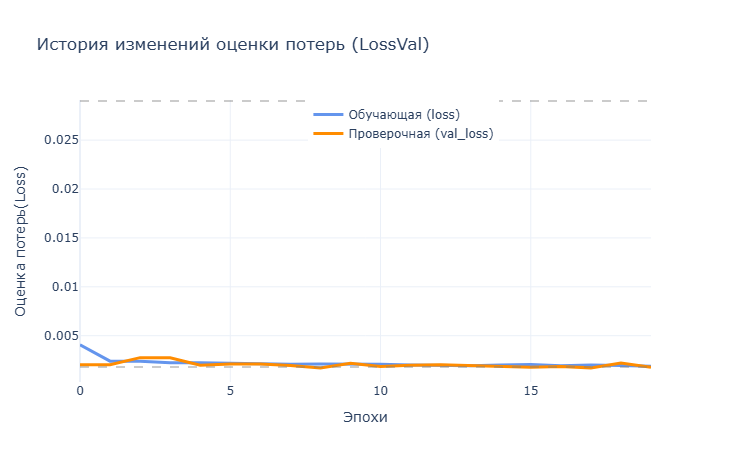

In [62]:
# Отобразить график изменения оценки потерь по эпохам обучения
print('Доступные метрики полной истории обучения:', totalHistoryDict_m4.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict_m4['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict_m4.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict_m4['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
mask = refHFib<=np.max(totalHistoryDict_m4['loss'])
mask = np.concatenate([mask[1:], [True]*1])
for y in refHFib[mask]:# Горизонтальные опорные линии (порядки величин)
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

# Настройки осей
fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)") # type="log",
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [63]:
totalHistoryDict_m4['val_loss'][-5:]

[0.0017705914797261357,
 0.0018479981226846576,
 0.001710694283246994,
 0.002208912279456854,
 0.0017657681601122022]

455/455 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
MAE :     0.027 (средняя абсолютная ошибка)
MSE :  0.001766 (среднеквадратичная ошибка)
RMSE:  0.042021 (кв. корень из среднеквадратичной ошибки)
R2  :     0.968 (коэфф. детерминации)


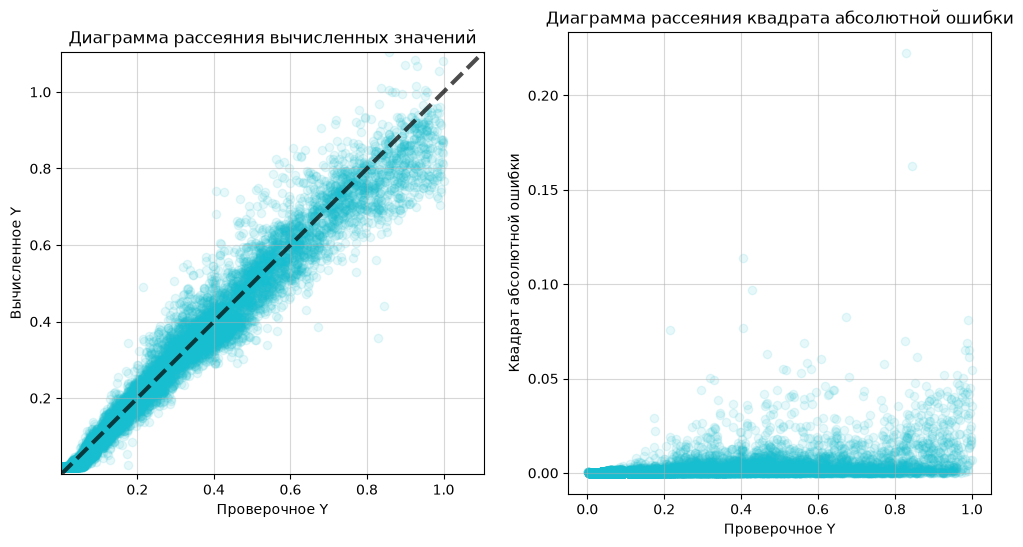

In [64]:
# Вычислить ответы НС на ПРОВЕРОЧНОЙ ЧАСТИ
yNorm_pred_m4 = model_m4.predict( xNorm_test [["carat", "color_digit", "cut_digit", "clarity_digit", 'x', 'y', 'z', 'depth', 'table']] ) # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов

# Вычислить метрики и построить графики, сравнивая ответы НС с ПРОВЕРОЧНОЙ ЧАСТЬЮ
GET_METRICS_SINGLE(yNorm_test, yNorm_pred_m4) # Вычислить метрики точности
PLOT34(yNorm_test, yNorm_pred_m4)   # Отобразить графики для вычисленных значений

Сеть с одним скрытым слоем достигла loss = 0,0021, val_loss = 0,0018–0,0022. Добавление второго слоя снизило loss до 0,0019–0,0020, а val_loss — до 0,0017–0,0021. Добавление третьего слоя не дало улучшения: loss остался на уровне 0,0019–0,0020, val_loss 0,0017–0,0024. Таким образом, двух скрытых слоёв достаточно для описания зависимости.

# Сравнение полученных моделей

Приведем все численные оценки всех моделей для более удобного сравнения.


      M1.
        Структура: '2вх -> 1вых' (3 параметра).
        Признаки: 'carat, clarity_digit'.
        ЭпохОбучения: '10'.
        MAE : 0.057 (средняя абсолютная ошибка)
        RMSE: 0.081678 (кв. корень из среднеквадратичной ошибки)
        R2  : 0.882 (коэфф. детерминации)

      M2.
        Структура: '2вх -> 100 (relu) -> 50 (relu) -> 1вых' (5 401 параметр).
        Признаки: 'carat, clarity_digit'.
        ЭпохОбучения: '27'.
        MAE : 0.038 (средняя абсолютная ошибка)
        RMSE: 0.062831 (кв. корень из среднеквадратичной ошибки)
        R2  : 0.930 (коэфф. детерминации)

      M3.
        Структура: '9вх -> 1вых' (без скрытых слоёв, 5 параметров).
        Признаки: 'carat, color_digit, cut_digit, clarity_digit', 'x', 'y', 'z', 'depth', 'table'.
        ЭпохОбучения: '20'.
        MAE : 0.050 (средняя абсолютная ошибка)
        RMSE: 0.071996 (кв. корень из среднеквадратичной ошибки)
        R2  : 0.907 (коэфф. детерминации)

      M4.
        Структура: '9вх -> 100 (relu) -> 50 (relu) -> 1вых' (5 601 параметр).
        Признаки: 'carat, color_digit, cut_digit, clarity_digit', 'x', 'y', 'z', 'depth', 'table'.
        ЭпохОбучения: '24'.
        MAE : 0.025 (средняя абсолютная ошибка)
        RMSE: 0.040696 (кв. корень из среднеквадратичной ошибки)
        R2  : 0.970 (коэфф. детерминации)

# Итоговые, сводные результаты и выводы.

Время затраченное на выполнение основных этапов работы, согласно методологии CRISP.

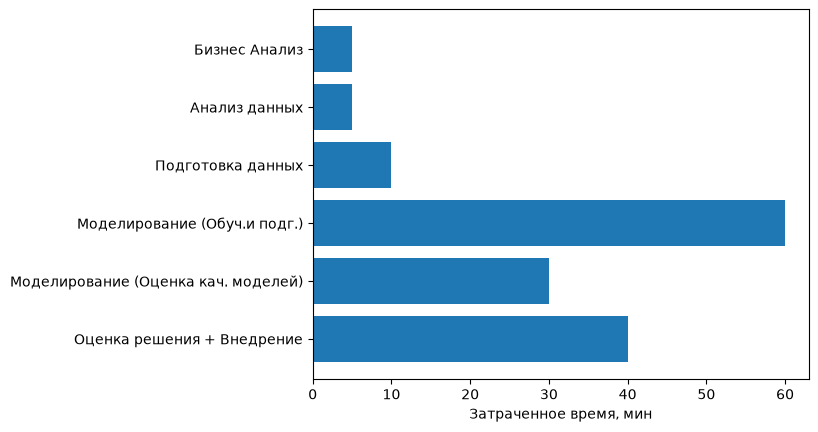

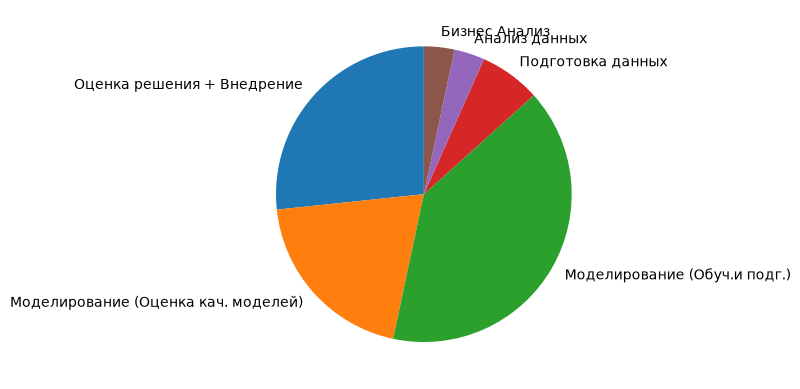

In [65]:
# Создадим датафрейм для хранения значений
dfSpendTimeLab2 = pd.DataFrame.from_dict(
{
  "1": {"step": "Бизнес Анализ",                       "duration, min" :  5  },
  "2": {"step": "Анализ данных",                       "duration, min" :  5  },
  "3": {"step": "Подготовка данных",                   "duration, min" :  10  },
  "4": {"step": "Моделирование (Обуч.и подг.)",        "duration, min" :  60  },
  "5": {"step": "Моделирование (Оценка кач. моделей)", "duration, min" :  30  },
  "6": {"step": "Оценка решения + Внедрение",          "duration, min" :  40  },
}
, orient="index"
).sort_index(ascending=False)

# Построить столбчатую диаграмму
fig = plt.figure()
plt.barh(y = dfSpendTimeLab2["step"], width= dfSpendTimeLab2["duration, min"], )
plt.xlabel("Затраченное время, мин")

# Построить круговую диаграмму
fig = plt.figure()
plt.pie(x= dfSpendTimeLab2["duration, min"], labels=dfSpendTimeLab2["step"],  startangle = 90 )

plt.show()

# Выводы по работе


Модели без скрытых слоёв описывают зависимость плоскостью, поэтому они не учитывают ускоряющийся рост цены с массой: на диаграммах рассеяния точки лежат дугой, модели дают отрицательные прогнозы для дешёвых бриллиантов и занижают цену дорогих. Добавление скрытых слоёв с нелинейной функцией активации relu при тех же признаках повышает точность. Увеличение числа слоёв помогает до определённого предела. Для m4 переход от одного скрытого слоя ко второму снизил loss с 0,0022 до 0,0019–0,0020, а третий слой улучшения не дал: loss остался на уровне 0,0019–0,0020. Для m2 второй скрытый слой снизил val_loss с 0,0041–0,0052 до ≈ 0,0039. Среди функций активации наилучший результат дала relu: при tanh и elu ошибка оказалась примерно на 15% выше.

Линейные модели обучаются за 1–2 эпохи. Модели со скрытыми слоями выходят на постоянный уровень ошибки за большее число эпох. Время одной эпохи при этом почти не зависит от структуры (≈ 1–2 с), поэтому общее время обучения определяется в основном числом эпох.

Нейронная сеть эффективна для нашего набора данных. Лучшая модель m4 описывают 96,9% изменчивости цены. 

Модели m3 и m4 обучены на одних и тех же признаках, но m4 точнее: R² 0,907 против 0,97. Причина — m3 не имеет скрытых слоёв и вычисляет линейную комбинацию признаков. m4 за счёт двух скрытых слоёв учитывает нелинейный характер зависимости (цена растёт быстрее массы) и взаимодействие признаков (влияние массы сильнее у камней высокой чистоты и цвета).

Добавление признаков x, y, z, depth, table почти не повысило точность (m3: 0,900 -> 0,907, m4: 0,969 -> 0,970), так как размеры камня дублируют информацию о массе, а пропорции depth и table слабо влияют на цену/